In [2]:
from glaciation_time_estimator.auxiliary_func.chunking_data import ChunkLoader
from glaciation_time_estimator.auxiliary_func.config_reader import read_config
import numpy as np 
import pandas as pd
from cmcrameri import cm
from matplotlib.ticker import PercentFormatter

In [3]:
colormap=cm.lipariS.colors
color_dd=colormap[2]
color_sev=colormap[3]
color_mod=colormap[0]


In [4]:
years=[y for y in range(2007,2010)]
config_dd = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/Validation_DARDAR/02_deg/2008_tracking/01_01.yaml")
config_mod = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/Validation_MODIS/n2o_2007_01_01.yaml")

In [5]:
def return_glac_df(a):
    return a[1]
loader_dd = ChunkLoader(years,config_dd,load_init_chunk=False)
glac_dfs_dd = loader_dd.execute_analysis(return_glac_df,load_clouds=False)
df_glac_dd = pd.concat(glac_dfs_dd,ignore_index=True)

Cloud_fps: {2007: '/nfs/ch4/wolke_scratch/dnikolo/GTE_Validation/DARDAR/Bulk_02/Final_results/2007_all.parquet', 2008: '/nfs/ch4/wolke_scratch/dnikolo/GTE_Validation/DARDAR/Bulk_02/Final_results/2008_all.parquet', 2009: '/nfs/ch4/wolke_scratch/dnikolo/GTE_Validation/DARDAR/Bulk_02/Final_results/2009_all.parquet'}


Loading years:   0%|          | 0/3 [00:00<?, ?year/s]

Loading years: 100%|██████████| 3/3 [00:10<00:00,  3.48s/year]


In [6]:
loader_mod = ChunkLoader([2007],config_mod,load_init_chunk=False)
glac_dfs_mod = loader_mod.execute_analysis(return_glac_df,load_clouds=False)
df_glac_mod = pd.concat(glac_dfs_mod,ignore_index=True)

Cloud_fps: {2007: '/wolke_scratch/dnikolo/GTE_Validation/Modis_optical_1_year/Final_results/2007_all.parquet'}


Loading years: 100%|██████████| 1/1 [00:02<00:00,  2.84s/year]


In [7]:
df_glac_mod

,Cloud_ID,Time [m],Magnitude,Glac_start_ind,Glac_peak_ind,Linear,line_rmse,Rate_arr,Mean_glac_rate,Glaciation time [h],...,min_temp,max_temp,pole,Hemisphere,Lifetime [h],Radius [km],Level,Optical Thickness,Cloud type,Season
0,26140,30,0.919928,0,2,False,0.152268,"[1.8926231375789158, 1.8926231375789158, 1.681...",1.822266,0.50,...,-12,-6,np,North,0.75,58.928336,Low,Thin,Cumulus,DJF
1,32983,60,0.574322,0,4,True,0.044444,"[0.574321985244751, 0.574321985244751, 0.57432...",0.574322,1.00,...,-12,-6,np,North,1.00,34.879340,Low,Thin,Cumulus,DJF
2,33022,90,0.780755,36,42,False,0.270240,"[0.011610397944688794, 0.011610397944688775, 0...",0.542125,1.50,...,-12,-6,np,North,11.00,53.226862,Low,Thin,Cumulus,DJF
3,34336,30,0.412718,0,2,False,0.113760,"[1.044780624782497, 1.044780624782497, 0.16740...",0.752321,0.50,...,-12,-6,np,North,3.75,20.726060,Alto,Medium,Altostratus,DJF
4,35218,45,0.474398,0,3,True,0.075069,"[0.6325304905573527, 0.6325304905573527, 0.632...",0.632530,0.75,...,-12,-6,np,North,0.75,29.978133,Low,Thin,Cumulus,DJF
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99460,4145084,90,0.415749,0,6,True,0.087043,"[0.27716606855392456, 0.27716606855392456, 0.2...",0.277166,1.50,...,-36,-30,sp,South,1.50,20.390784,Alto,Medium,Altostratus,DJF
99461,4145089,120,0.476124,0,8,True,0.059934,"[0.23806193470954895, 0.23806193470954895, 0.2...",0.238062,2.00,...,-36,-30,sp,South,2.00,26.038986,Alto,Thick,Nimbostratus,DJF
99462,4145106,75,0.550084,0,5,True,0.072601,"[0.4400672912597656, 0.4400672912597656, 0.440...",0.440067,1.25,...,-36,-30,sp,South,1.50,51.102135,Alto,Thick,Nimbostratus,DJF
99463,4145204,150,0.471302,0,10,False,0.115325,"[0.4710304205960332, 0.4710304205960332, 0.471...",0.341339,2.50,...,-36,-30,sp,South,2.50,47.366630,Alto,NaN,None,DJF


In [8]:
ALLOWED_CTH_DEV=1000

def _check_val_seviri_coincidence(row):
    points_of_interest = row["val_cth_hist"] > 0
    if type(row["cth_hist"]) == float:
            # N+=1
            return False
    cth_deviations = np.abs(row["cth_hist"][points_of_interest] - row["val_cth_hist"][points_of_interest])
    if cth_deviations.size == 0:
        return False
    mean_height_dev = cth_deviations.mean()  
    if mean_height_dev > ALLOWED_CTH_DEV:
        return False
    return True

def _get_val_seviri_coincidence(row):
    if "val_seviri_coincidence" not in row.keys():
        return _check_val_seviri_coincidence(row)
    else:
        return row["val_seviri_coincidence"]

In [9]:
df_glac_dd["val_seviri_coincidence"]=df_glac_dd.apply(_check_val_seviri_coincidence,axis=1)
df_glac_mod["val_seviri_coincidence"]=df_glac_mod.apply(_check_val_seviri_coincidence,axis=1)

In [10]:
ALLOWED_CTH_DEV=1000

def get_mean_dd_ice_frac_hist(row):
    if_hist = row["val_ice_frac_hist"]
    if (np.isnan(if_hist) | (if_hist==-1)).all():
        return np.nan
    return if_hist[~np.isnan(if_hist)].mean()

def get_mean_dd_ice_frac_dev(row):
    if _get_val_seviri_coincidence(row):
        if_hist_dev = row["val_ice_frac_dev_hist"]
        if (np.isnan(if_hist_dev) | (if_hist_dev==-99)).all():
            return np.nan
        if_hist_dev = if_hist_dev[(~np.isnan(if_hist_dev)) & (if_hist_dev >-99)]
        if if_hist_dev.size>0:
            return if_hist_dev.mean()
        else:
            return np.nan
    else: return np.nan

def get_if_dev_same_cloud(row):
    try:
        if _get_val_seviri_coincidence(row):
            if_hist_dev = row["val_ice_frac_dev_hist"]
            if_hist_dev = if_hist_dev[~np.isnan(if_hist_dev)]
            if_hist_dev = if_hist_dev[if_hist_dev >-99]
            if if_hist_dev.size>0:
                return if_hist_dev.mean()
            else:
                return np.nan
        else:
            return np.nan
    except Exception as e:
        print(f"Error processing row: {e} {row['cth_hist']}")
        return np.nan
N=1
def get_if_glac_peak_same_cloud(row):
    if _get_val_seviri_coincidence(row):
        if_hist = row["val_ice_frac_hist"]
        peak_value = if_hist[row["Glac_peak_ind"]]   
        if peak_value >=0:
            return peak_value
        else:
            return np.nan
    else:
        return np.nan
    
def get_claas_if_glac_peak_same_cloud(row):
    if _get_val_seviri_coincidence(row):
        if_hist = row["val_pix_claas_if_hist"]
        peak_value = if_hist[row["Glac_peak_ind"]]   
        
        if peak_value >=0:
            return peak_value
        else:
            return np.nan
    else:
        return np.nan

def check_dd_seviri_coincidence(row):
    points_of_interest = row["val_cth_hist"] > 0
    if type(row["cth_hist"]) == float:
            N+=1
            return np.nan 
    cth_deviations = np.abs(row["cth_hist"][points_of_interest] - row["val_cth_hist"][points_of_interest])
    if cth_deviations.size == 0:
        return False
    mean_height_dev = cth_deviations.mean()  
    if mean_height_dev > ALLOWED_CTH_DEV:
        return False
    return True


def get_seviri_peak_if(row):
    if_hist = row["val_pix_claas_if_hist"]
    return if_hist[row["Glac_peak_ind"]]

# def get_seviri_pre_peak_if(row: pd.Series,idx: int):
#     if _get_val_seviri_coincidence(row):
#         if_hist = row["val_pix_claas_if_hist"]
#         if ((row["Glac_peak_ind"]-idx)>=0) and ((row["Glac_peak_ind"]-idx)<len(if_hist)):
#             return if_hist[row["Glac_peak_ind"]-idx]
#         return np.nan
#     else:
        # return np.nan

def get_seviri_pre_peak_if(row: pd.Series,idx: int):
    if_hist = row["ice_frac_hist"]
    if ((row["Glac_peak_ind"]-idx)>=0) and ((row["Glac_peak_ind"]-idx)<len(if_hist)):
        return if_hist[row["Glac_peak_ind"]-idx]
    return np.nan

def get_dd_pre_peak_if(row: pd.Series,idx: int):
    if _get_val_seviri_coincidence(row):
        if_hist = row["val_ice_frac_hist"]
        if ((row["Glac_peak_ind"]-idx)>=0) and ((row["Glac_peak_ind"]-idx)<len(if_hist)):
            return if_hist[row["Glac_peak_ind"]-idx]
        return np.nan
    else:
        return np.nan

In [11]:
for pre_peak_idx in range(-5, 5):
    df_glac_mod[f"seviri_{pre_peak_idx}_prepeak_if"] = df_glac_mod.apply(
        get_seviri_pre_peak_if,
        axis=1,
        args=(pre_peak_idx,)
    )
    df_glac_dd[f"seviri_{pre_peak_idx}_prepeak_if"] = df_glac_dd.apply(
        get_seviri_pre_peak_if,
        axis=1,
        args=(pre_peak_idx,)
    )
    df_glac_dd[f"val_{pre_peak_idx}_prepeak_if"] = df_glac_dd.apply(
        get_dd_pre_peak_if,
        axis=1,
        args=(pre_peak_idx,)
    )
    df_glac_mod[f"val_{pre_peak_idx}_prepeak_if"] = df_glac_mod.apply(
            get_dd_pre_peak_if,
            axis=1,
            args=(pre_peak_idx,)
        )
    

# Plots

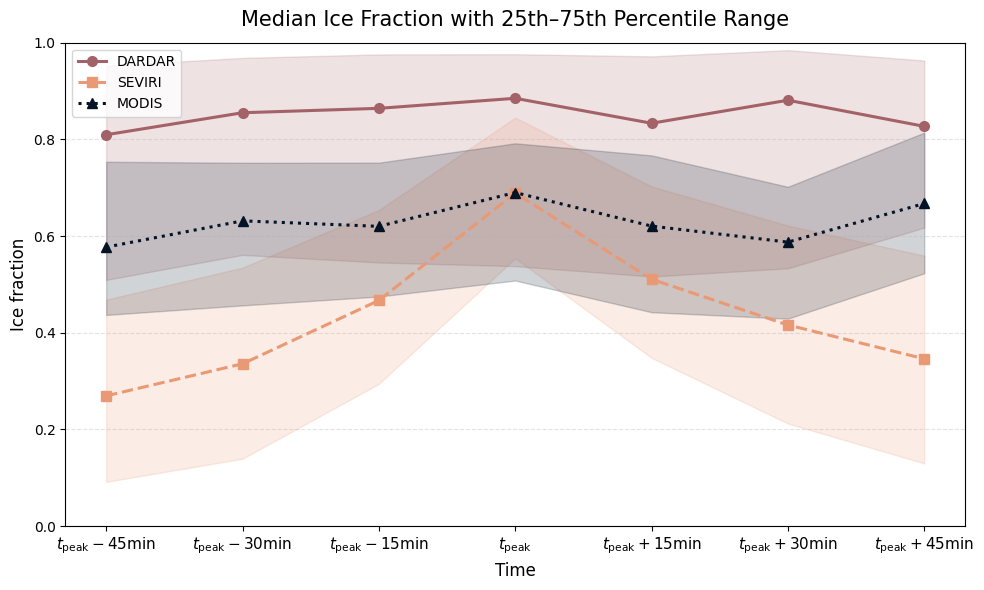

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# timesteps in plotting order

timesteps = [i for i in range(3, -4, -1)]

# corresponding column names
dardar_cols = [f"val_{i}_prepeak_if" for i in timesteps]
modis_cols  = [f"val_{i}_prepeak_if" for i in timesteps]
seviri_cols = [f"seviri_{i}_prepeak_if" for i in timesteps]

x_labels = [
    r"$t_{\mathrm{peak}}-45\mathrm{min}$",
    r"$t_{\mathrm{peak}}-30\mathrm{min}$",
    r"$t_{\mathrm{peak}}-15\mathrm{min}$",
    r"$t_{\mathrm{peak}}$",
    r"$t_{\mathrm{peak}}+15\mathrm{min}$",
    r"$t_{\mathrm{peak}}+30\mathrm{min}$",
    r"$t_{\mathrm{peak}}+45\mathrm{min}$",
]


def clean_vals(series):
    vals = series.dropna()
    vals = vals[(vals >= 0) & (vals <= 1)]
    return vals.values

def median_q25_q75(vals):
    if len(vals) == 0:
        return np.nan, np.nan, np.nan
    q25 = np.percentile(vals, 25)
    med = np.percentile(vals, 50)
    q75 = np.percentile(vals, 75)
    return q25, med, q75

# store percentile stats
dardar_q25, dardar_med, dardar_q75 = [], [], []
seviri_q25, seviri_med, seviri_q75 = [], [], []
modis_q25, modis_med, modis_q75 = [], [], []

for dd_col, sev_col, mod_col in zip(dardar_cols, seviri_cols, modis_cols):
    # DARDAR
    dd_vals = clean_vals(df_glac_dd[dd_col])
    q25, med, q75 = median_q25_q75(dd_vals)
    dardar_q25.append(q25)
    dardar_med.append(med)
    dardar_q75.append(q75)

    # SEVIRI
    sev_vals = clean_vals(df_glac_dd[sev_col])
    q25, med, q75 = median_q25_q75(sev_vals)
    seviri_q25.append(q25)
    seviri_med.append(med)
    seviri_q75.append(q75)

    # MODIS
    mod_vals = clean_vals(df_glac_mod[mod_col])
    q25, med, q75 = median_q25_q75(mod_vals)
    modis_q25.append(q25)
    modis_med.append(med)
    modis_q75.append(q75)

# convert to arrays
dardar_q25 = np.array(dardar_q25)
dardar_med = np.array(dardar_med)
dardar_q75 = np.array(dardar_q75)

seviri_q25 = np.array(seviri_q25)
seviri_med = np.array(seviri_med)
seviri_q75 = np.array(seviri_q75)

modis_q25 = np.array(modis_q25)
modis_med = np.array(modis_med)
modis_q75 = np.array(modis_q75)

x = np.arange(len(x_labels))

plt.figure(figsize=(10, 6))

# median lines
line1, = plt.plot(
    x, dardar_med,
    marker="o", linestyle="-", linewidth=2.2, markersize=7,
    label="DARDAR", color = color_dd
)

line2, = plt.plot(
    x, seviri_med,
    marker="s", linestyle="--", linewidth=2.2, markersize=7,
    label="SEVIRI", color = color_sev
)

line3, = plt.plot(
    x, modis_med,
    marker="^", linestyle=":", linewidth=2.2, markersize=7,
    label="MODIS", color = color_mod
)

# shaded percentile bands
plt.fill_between(
    x, dardar_q25, dardar_q75,
    color=line1.get_color(), alpha=0.18
)

plt.fill_between(
    x, seviri_q25, seviri_q75,
    color=line2.get_color(), alpha=0.18
)

plt.fill_between(
    x, modis_q25, modis_q75,
    color=line3.get_color(), alpha=0.18
)

plt.xticks(x, x_labels, fontsize=11)
plt.ylabel("Ice fraction", fontsize=12)
plt.xlabel("Time", fontsize=12)
plt.title("Median Ice Fraction with 25th–75th Percentile Range", fontsize=15, pad=12)

plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

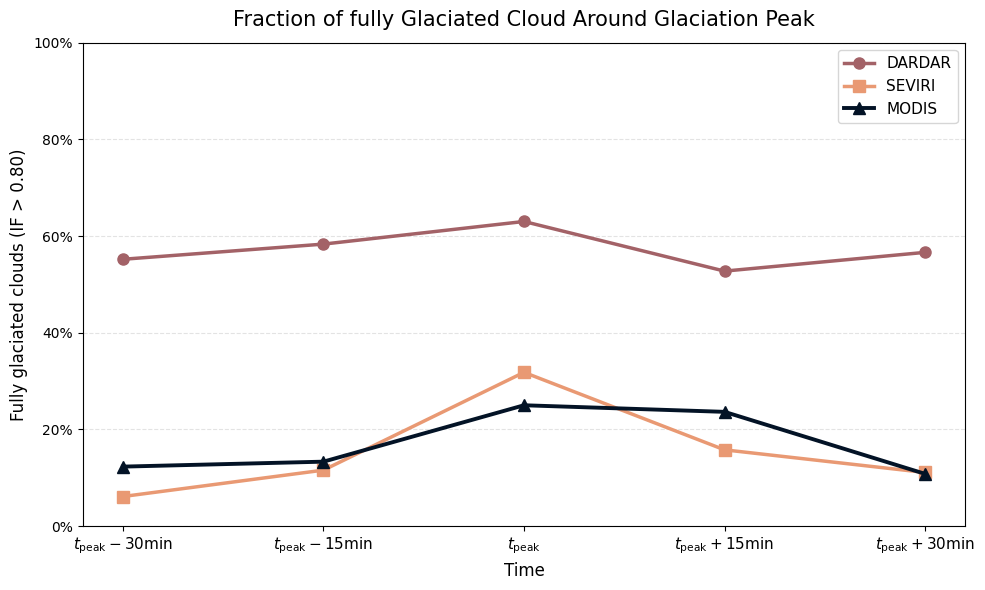

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# timesteps in plotting order
timesteps = [i for i in range(2, -3, -1)]

ice_phase_thresh = 0.8

# corresponding column names
dardar_cols = [f"val_{i}_prepeak_if" for i in timesteps]
modis_cols = [f"val_{i}_prepeak_if" for i in timesteps]
seviri_cols = [f"seviri_{i}_prepeak_if" for i in timesteps]

x_labels = [
    r"$t_{\mathrm{peak}}-30\mathrm{min}$",
    r"$t_{\mathrm{peak}}-15\mathrm{min}$",
    r"$t_{\mathrm{peak}}$",
    r"$t_{\mathrm{peak}}+15\mathrm{min}$",
    r"$t_{\mathrm{peak}}+30\mathrm{min}$"
]
x = np.arange(len(x_labels))

dardar_frac, seviri_frac, modis_frac = [], [], []
dardar_n, seviri_n, modis_n = [], [], []

for dd_col, sev_col, mod_col in zip(dardar_cols, seviri_cols, modis_cols):
    # DARDAR
    dd_vals = df_glac_dd[dd_col].dropna()
    dd_vals = dd_vals[(dd_vals >= 0) & (dd_vals <= 1)]
    dardar_frac.append((dd_vals > ice_phase_thresh).mean() if len(dd_vals) > 0 else np.nan)
    dardar_n.append(len(dd_vals))

    # SEVIRI
    sev_vals = df_glac_dd[sev_col].dropna()
    sev_vals = sev_vals[(sev_vals >= 0) & (sev_vals <= 1)]
    seviri_frac.append((sev_vals > ice_phase_thresh).mean() if len(sev_vals) > 0 else np.nan)
    seviri_n.append(len(sev_vals))

    # MODIS
    mod_vals = df_glac_mod[mod_col].dropna()
    mod_vals = mod_vals[(mod_vals >= 0) & (mod_vals <= 1)]
    modis_frac.append((mod_vals > ice_phase_thresh).mean() if len(mod_vals) > 0 else np.nan)
    modis_n.append(len(mod_vals))

dardar_frac = np.array(dardar_frac)
seviri_frac = np.array(seviri_frac)
modis_frac = np.array(modis_frac)

plt.figure(figsize=(10, 6))

plt.plot(
    x, dardar_frac,
    marker="o", linestyle="-", linewidth=2.5, markersize=8,
    label="DARDAR", color = color_dd
)

plt.plot(
    x, seviri_frac,
    marker="s", linestyle="-", linewidth=2.5, markersize=8,
    label="SEVIRI", color = color_sev
)

plt.plot(
    x, modis_frac,
    marker="^", linestyle="-", linewidth=2.8, markersize=8,
    label="MODIS", color = color_mod
)

# optional point labels with different offsets to avoid overlap
# for xi, y in zip(x, dardar_frac):
#     if not np.isnan(y):
#         plt.text(xi, y + 0.025, f"{y:.2f}", ha="center", va="bottom", fontsize=9)

# for xi, y in zip(x, seviri_frac):
#     if not np.isnan(y):
#         plt.text(xi, y - 0.035, f"{y:.2f}", ha="center", va="top", fontsize=9)

# for xi, y in zip(x, modis_frac):
#     if not np.isnan(y):
#         plt.text(xi, y + 0.055, f"{y:.2f}", ha="center", va="bottom", fontsize=9)

plt.xticks(x, x_labels, fontsize=11)
# plt.ylabel(f"Fraction of fully glaciated clouds (IF > {ice_phase_thresh:.2f})", fontsize=12)
plt.xlabel("Time", fontsize=12)
plt.title("Fraction of fully Glaciated Cloud Around Glaciation Peak", fontsize=15, pad=12)
plt.ylabel(
    f"Fully glaciated clouds (IF > {ice_phase_thresh:.2f})",
    fontsize=12
)

plt.ylim(0, 1)
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1))
# plt.ylim(0, 1)
plt.xlim(-0.2, len(x_labels) - 0.8)
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True, fontsize=11)
plt.tight_layout()
plt.show()


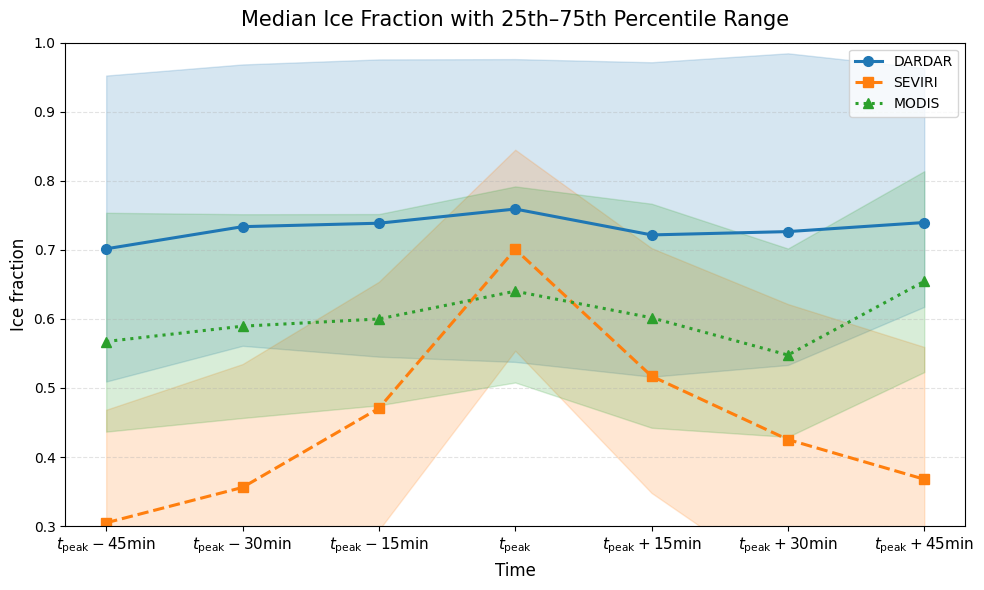

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# timesteps in plotting order
timesteps = [i for i in range(3, -4, -1)]


# corresponding column names
dardar_cols = [f"val_{i}_prepeak_if" for i in timesteps]
modis_cols  = [f"val_{i}_prepeak_if" for i in timesteps]
seviri_cols = [f"seviri_{i}_prepeak_if" for i in timesteps]

x_labels = [
    r"$t_{\mathrm{peak}}-45\mathrm{min}$",
    r"$t_{\mathrm{peak}}-30\mathrm{min}$",
    r"$t_{\mathrm{peak}}-15\mathrm{min}$",
    r"$t_{\mathrm{peak}}$",
    r"$t_{\mathrm{peak}}+15\mathrm{min}$",
    r"$t_{\mathrm{peak}}+30\mathrm{min}$",
    r"$t_{\mathrm{peak}}+45\mathrm{min}$",
]


def clean_vals(series):
    vals = series.dropna()
    vals = vals[(vals >= 0) & (vals <= 1)]
    return vals.values

def median_q25_q75(vals):
    if len(vals) == 0:
        return np.nan, np.nan, np.nan
    q25 = np.percentile(vals, 25)
    med = np.nanmean(vals)
    q75 = np.percentile(vals, 75)
    return q25, med, q75

# store percentile stats
dardar_q25, dardar_med, dardar_q75 = [], [], []
seviri_q25, seviri_med, seviri_q75 = [], [], []
modis_q25, modis_med, modis_q75 = [], [], []

for dd_col, sev_col, mod_col in zip(dardar_cols, seviri_cols, modis_cols):
    # DARDAR
    dd_vals = clean_vals(df_glac_dd[dd_col])
    q25, med, q75 = median_q25_q75(dd_vals)
    dardar_q25.append(q25)
    dardar_med.append(med)
    dardar_q75.append(q75)

    # SEVIRI
    sev_vals = clean_vals(df_glac_dd[sev_col])
    q25, med, q75 = median_q25_q75(sev_vals)
    seviri_q25.append(q25)
    seviri_med.append(med)
    seviri_q75.append(q75)

    # MODIS
    mod_vals = clean_vals(df_glac_mod[mod_col])
    q25, med, q75 = median_q25_q75(mod_vals)
    modis_q25.append(q25)
    modis_med.append(med)
    modis_q75.append(q75)

# convert to arrays
dardar_q25 = np.array(dardar_q25)
dardar_med = np.array(dardar_med)
dardar_q75 = np.array(dardar_q75)

seviri_q25 = np.array(seviri_q25)
seviri_med = np.array(seviri_med)
seviri_q75 = np.array(seviri_q75)

modis_q25 = np.array(modis_q25)
modis_med = np.array(modis_med)
modis_q75 = np.array(modis_q75)

x = np.arange(len(x_labels))

plt.figure(figsize=(10, 6))

# median lines
line1, = plt.plot(
    x, dardar_med,
    marker="o", linestyle="-", linewidth=2.2, markersize=7,
    label="DARDAR"
)

line2, = plt.plot(
    x, seviri_med,
    marker="s", linestyle="--", linewidth=2.2, markersize=7,
    label="SEVIRI"
)

line3, = plt.plot(
    x, modis_med,
    marker="^", linestyle=":", linewidth=2.2, markersize=7,
    label="MODIS"
)

# shaded percentile bands
plt.fill_between(
    x, dardar_q25, dardar_q75,
    color=line1.get_color(), alpha=0.18
)

plt.fill_between(
    x, seviri_q25, seviri_q75,
    color=line2.get_color(), alpha=0.18
)

plt.fill_between(
    x, modis_q25, modis_q75,
    color=line3.get_color(), alpha=0.18
)

plt.xticks(x, x_labels, fontsize=11)
plt.ylabel("Ice fraction", fontsize=12)
plt.xlabel("Time", fontsize=12)
plt.title("Median Ice Fraction with 25th–75th Percentile Range", fontsize=15, pad=12)

plt.ylim(0.3, 1)
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

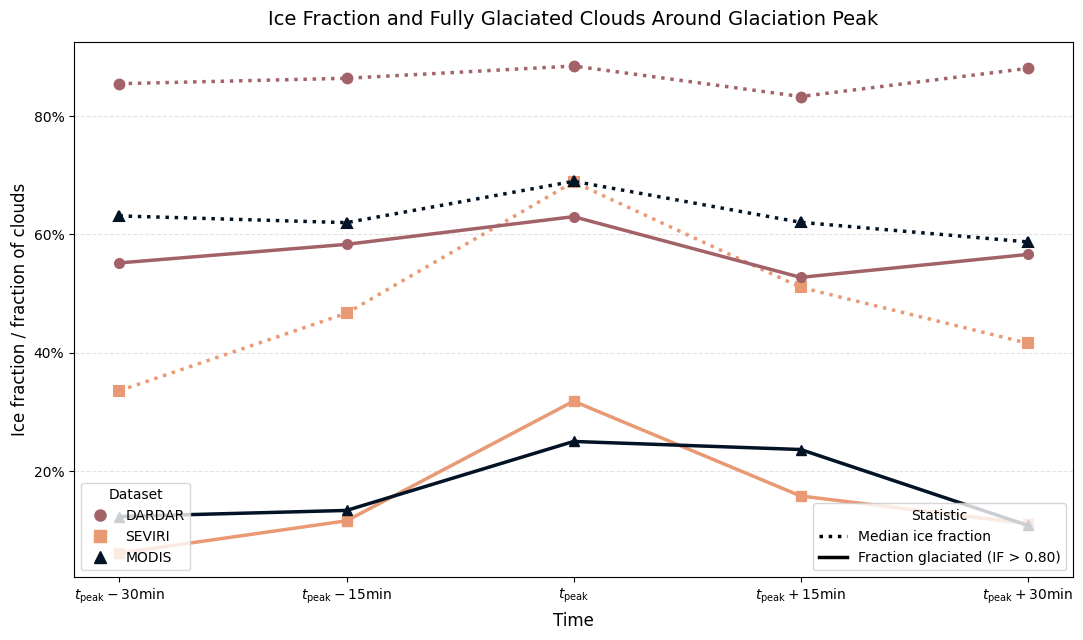

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

# ------------------------------------------------------------------
# Configuration
# ------------------------------------------------------------------
timesteps = list(range(2, -3, -1))
ice_phase_thresh = 0.8

dardar_cols = [f"val_{i}_prepeak_if" for i in timesteps]
modis_cols  = [f"val_{i}_prepeak_if" for i in timesteps]
seviri_cols = [f"seviri_{i}_prepeak_if" for i in timesteps]

x_labels = [
    # r"$t_{\mathrm{peak}}-45\mathrm{min}$",
    r"$t_{\mathrm{peak}}-30\mathrm{min}$",
    r"$t_{\mathrm{peak}}-15\mathrm{min}$",
    r"$t_{\mathrm{peak}}$",
    r"$t_{\mathrm{peak}}+15\mathrm{min}$",
    r"$t_{\mathrm{peak}}+30\mathrm{min}$",
    # r"$t_{\mathrm{peak}}+45\mathrm{min}$",
]

x = np.arange(len(x_labels))


# ------------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------------
def clean_vals(series):
    """Remove missing and invalid ice-fraction values."""
    vals = series.dropna()
    vals = vals[(vals >= 0) & (vals <= 1)]
    return vals.to_numpy()


def calculate_stats(df, columns, threshold):
    """Calculate median, quartiles, and fraction above the threshold."""
    q25_values = []
    median_values = []
    q75_values = []
    glaciated_fractions = []
    sample_sizes = []

    for column in columns:
        vals = clean_vals(df[column])
        sample_sizes.append(len(vals))

        if len(vals) == 0:
            q25_values.append(np.nan)
            median_values.append(np.nan)
            q75_values.append(np.nan)
            glaciated_fractions.append(np.nan)
        else:
            q25_values.append(np.percentile(vals, 25))
            median_values.append(np.median(vals))
            q75_values.append(np.percentile(vals, 75))
            glaciated_fractions.append(np.mean(vals > threshold))

    return {
        "q25": np.asarray(q25_values),
        "median": np.asarray(median_values),
        "q75": np.asarray(q75_values),
        "fraction": np.asarray(glaciated_fractions),
        "n": np.asarray(sample_sizes),
    }


# ------------------------------------------------------------------
# Calculate statistics
# ------------------------------------------------------------------
dardar = calculate_stats(
    df_glac_dd,
    dardar_cols,
    ice_phase_thresh,
)

seviri = calculate_stats(
    df_glac_dd,
    seviri_cols,
    ice_phase_thresh,
)

modis = calculate_stats(
    df_glac_mod,
    modis_cols,
    ice_phase_thresh,
)


# ------------------------------------------------------------------
# Dataset appearance
# ------------------------------------------------------------------
datasets = {
    "DARDAR": {
        "stats": dardar,
        "color": color_dd,
        "marker": "o",
    },
    "SEVIRI": {
        "stats": seviri,
        "color": color_sev,
        "marker": "s",
    },
    "MODIS": {
        "stats": modis,
        "color": color_mod,
        "marker": "^",
    },
}


# ------------------------------------------------------------------
# Combined plot
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 6.5))

for name, config in datasets.items():
    stats = config["stats"]
    color = config["color"]
    marker = config["marker"]

    # Median ice fraction: dotted
    ax.plot(
        x,
        stats["median"],
        color=color,
        marker=marker,
        linestyle=":",
        linewidth=2.5,
        markersize=7,
        # markerfacecolor="white",
        markeredgewidth=1.5,
        zorder=3,
    )

    # Interquartile range associated with the median
    # ax.fill_between(
    #     x,
    #     stats["q25"],
    #     stats["q75"],
    #     color=color,
    #     alpha=0.12,
    #     linewidth=0,
    #     zorder=1,
    # )

    # Fraction fully glaciated: solid
    ax.plot(
        x,
        stats["fraction"],
        color=color,
        marker=marker,
        linestyle="-",
        linewidth=2.5,
        markersize=7,
        zorder=4,
    )


# ------------------------------------------------------------------
# Separate legends for datasets and line meanings
# ------------------------------------------------------------------
dataset_handles = [
    Line2D(
        [0], [0],
        color=config["color"],
        marker=config["marker"],
        linestyle="none",
        markersize=8,
        label=name,
    )
    for name, config in datasets.items()
]

metric_handles = [
    Line2D(
        [0], [0],
        color="black",
        linestyle=":",
        linewidth=2.5,
        label="Median ice fraction",
    ),
    Line2D(
        [0], [0],
        color="black",
        linestyle="-",
        linewidth=2.5,
        label=fr"Fraction glaciated (IF > {ice_phase_thresh:.2f})",
    ),
]

dataset_legend = ax.legend(
    handles=dataset_handles,
    title="Dataset",
    loc="lower left",
    frameon=True,
)

ax.add_artist(dataset_legend)

ax.legend(
    handles=metric_handles,
    title="Statistic",
    loc="lower right",
    frameon=True,
)


# ------------------------------------------------------------------
# Formatting
# ------------------------------------------------------------------
ax.set_xticks(x)
ax.set_xticklabels(x_labels, fontsize=10)

ax.set_xlabel("Time", fontsize=12)
ax.set_ylabel("Ice fraction / fraction of clouds", fontsize=12)

ax.set_title(
    "Ice Fraction and Fully Glaciated Clouds Around Glaciation Peak",
    fontsize=14,
    pad=12,
)

ax.set_xlim(-0.2, len(x_labels) - 0.8)
# ax.set_ylim(0, 1)

# Both quantities range from 0 to 1, so percentages can represent both.
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.35,
)

fig.tight_layout()
plt.show()

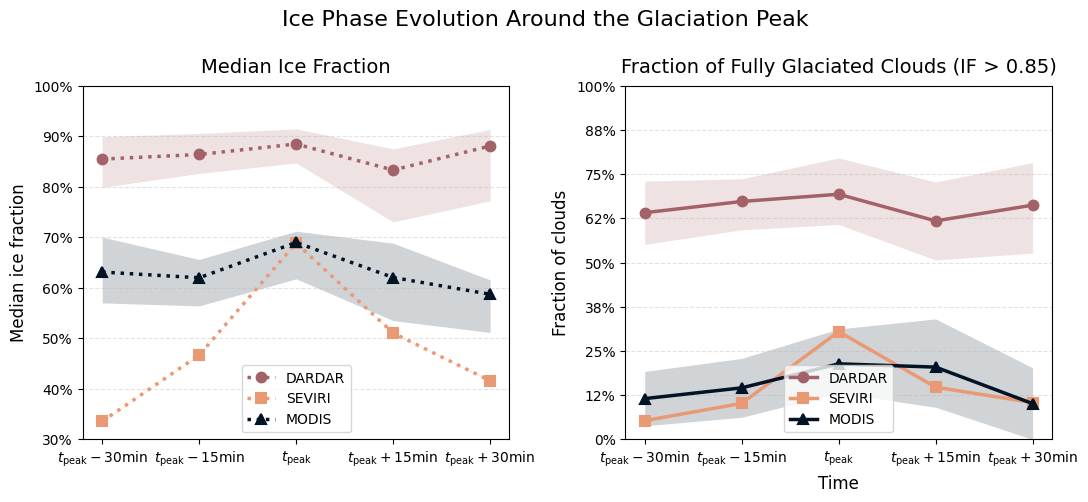

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

# ------------------------------------------------------------------
# Configuration
# ------------------------------------------------------------------
timesteps = list(range(2, -3, -1))
ice_phase_thresh = 0.85

n_bootstrap = 100
confidence_level = 90
random_seed = 42

dardar_cols = [f"val_{i}_prepeak_if" for i in timesteps]
modis_cols  = [f"val_{i}_prepeak_if" for i in timesteps]
seviri_cols = [f"seviri_{i}_prepeak_if" for i in timesteps]

x_labels = [
    r"$t_{\mathrm{peak}}-30\mathrm{min}$",
    r"$t_{\mathrm{peak}}-15\mathrm{min}$",
    r"$t_{\mathrm{peak}}$",
    r"$t_{\mathrm{peak}}+15\mathrm{min}$",
    r"$t_{\mathrm{peak}}+30\mathrm{min}$",
]

x = np.arange(len(x_labels))

# A single reproducible random-number generator
rng = np.random.default_rng(random_seed)


# ------------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------------
def clean_vals(series):
    """Remove missing and invalid ice-fraction values."""
    vals = series.dropna()
    vals = vals[(vals >= 0) & (vals <= 1)]
    return vals.to_numpy()


def bootstrap_confidence_intervals(
    vals,
    threshold,
    n_bootstrap=5000,
    confidence_level=95,
    rng=None,
):
    """
    Calculate percentile-bootstrap confidence intervals for:

    1. Median ice fraction
    2. Fraction of values above the glaciation threshold
    """
    if len(vals) == 0:
        return np.nan, np.nan, np.nan, np.nan

    if rng is None:
        rng = np.random.default_rng()

    n = len(vals)

    # Shape: (number of bootstrap samples, original sample size)
    bootstrap_indices = rng.integers(
        low=0,
        high=n,
        size=(n_bootstrap, n),
    )
    bootstrap_samples = vals[bootstrap_indices]

    # Bootstrap distributions
    bootstrap_medians = np.median(bootstrap_samples, axis=1)
    bootstrap_fractions = np.mean(
        bootstrap_samples > threshold,
        axis=1,
    )

    alpha = (100 - confidence_level) / 2

    median_low, median_high = np.percentile(
        bootstrap_medians,
        [alpha, 100 - alpha],
    )

    fraction_low, fraction_high = np.percentile(
        bootstrap_fractions,
        [alpha, 100 - alpha],
    )

    return (
        median_low,
        median_high,
        fraction_low,
        fraction_high,
    )


def calculate_stats(
    df,
    columns,
    threshold,
    n_bootstrap=5000,
    confidence_level=95,
    rng=None,
):
    """Calculate point estimates and bootstrap confidence intervals."""
    median_values = []
    glaciated_fractions = []

    median_ci_low = []
    median_ci_high = []

    fraction_ci_low = []
    fraction_ci_high = []

    sample_sizes = []

    for column in columns:
        vals = clean_vals(df[column])
        sample_sizes.append(len(vals))

        if len(vals) == 0:
            median_values.append(np.nan)
            glaciated_fractions.append(np.nan)

            median_ci_low.append(np.nan)
            median_ci_high.append(np.nan)

            fraction_ci_low.append(np.nan)
            fraction_ci_high.append(np.nan)

            continue

        # Point estimates
        median_values.append(np.median(vals))
        glaciated_fractions.append(np.mean(vals > threshold))

        # Bootstrap confidence intervals
        med_low, med_high, frac_low, frac_high = (
            bootstrap_confidence_intervals(
                vals=vals,
                threshold=threshold,
                n_bootstrap=n_bootstrap,
                confidence_level=confidence_level,
                rng=rng,
            )
        )

        median_ci_low.append(med_low)
        median_ci_high.append(med_high)

        fraction_ci_low.append(frac_low)
        fraction_ci_high.append(frac_high)

    return {
        "median": np.asarray(median_values),
        "median_ci_low": np.asarray(median_ci_low),
        "median_ci_high": np.asarray(median_ci_high),
        "fraction": np.asarray(glaciated_fractions),
        "fraction_ci_low": np.asarray(fraction_ci_low),
        "fraction_ci_high": np.asarray(fraction_ci_high),
        "n": np.asarray(sample_sizes),
    }


# ------------------------------------------------------------------
# Calculate statistics
# ------------------------------------------------------------------
dardar = calculate_stats(
    df=df_glac_dd,
    columns=dardar_cols,
    threshold=ice_phase_thresh,
    n_bootstrap=n_bootstrap,
    confidence_level=confidence_level,
    rng=rng,
)

seviri = calculate_stats(
    df=df_glac_dd,
    columns=seviri_cols,
    threshold=ice_phase_thresh,
    n_bootstrap=n_bootstrap,
    confidence_level=confidence_level,
    rng=rng,
)

modis = calculate_stats(
    df=df_glac_mod,
    columns=modis_cols,
    threshold=ice_phase_thresh,
    n_bootstrap=n_bootstrap,
    confidence_level=confidence_level,
    rng=rng,
)


# ------------------------------------------------------------------
# Dataset appearance
# ------------------------------------------------------------------
datasets = {
    "DARDAR": {
        "stats": dardar,
        "color": color_dd,
        "marker": "o",
    },
    "SEVIRI": {
        "stats": seviri,
        "color": color_sev,
        "marker": "s",
    },
    "MODIS": {
        "stats": modis,
        "color": color_mod,
        "marker": "^",
    },
}


# ------------------------------------------------------------------
# Two-panel plot
# ------------------------------------------------------------------
fig, (ax_med, ax_frac) = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(11, 5),
    sharex=True,
    # sharey=True,
)

for name, config in datasets.items():
    stats = config["stats"]
    color = config["color"]
    marker = config["marker"]

    # --------------------------------------------------------------
    # Top subplot: median ice fraction
    # --------------------------------------------------------------
    ax_med.fill_between(
        x,
        stats["median_ci_low"],
        stats["median_ci_high"],
        color=color,
        alpha=0.18,
        linewidth=0,
        zorder=1,
    )

    ax_med.plot(
        x,
        stats["median"],
        color=color,
        marker=marker,
        linestyle=":",
        linewidth=2.5,
        markersize=7,
        markeredgewidth=1.5,
        label=name,
        zorder=3,
    )

    # --------------------------------------------------------------
    # Bottom subplot: fraction fully glaciated
    # --------------------------------------------------------------
    ax_frac.fill_between(
        x,
        stats["fraction_ci_low"],
        stats["fraction_ci_high"],
        color=color,
        alpha=0.18,
        linewidth=0,
        zorder=1,
    )

    ax_frac.plot(
        x,
        stats["fraction"],
        color=color,
        marker=marker,
        linestyle="-",
        linewidth=2.5,
        markersize=7,
        markeredgewidth=1.5,
        label=name,
        zorder=3,
    )


# ------------------------------------------------------------------
# Formatting
# ------------------------------------------------------------------
ax_med.set_title(
    "Median Ice Fraction",
    fontsize=14,
    pad=10,
)

ax_frac.set_title(
    fr"Fraction of Fully Glaciated Clouds (IF > {ice_phase_thresh:.2f})",
    fontsize=14,
    pad=10,
)

ax_med.set_ylabel("Median ice fraction", fontsize=12)
ax_frac.set_ylabel("Fraction of clouds", fontsize=12)
ax_frac.set_xlabel("Time", fontsize=12)

ax_frac.set_ylim(0, 0.8)
ax_frac.yaxis.set_major_formatter(
        PercentFormatter(xmax=0.8)
    )
ax_med.set_ylim(0.3, 1.0)
ax_med.yaxis.set_major_formatter(
        PercentFormatter(xmax=1)
    )


for ax in (ax_med, ax_frac):
    ax.set_xlim(-0.2, len(x_labels) - 0.8)
    
    

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.35,
    )

    ax.legend(
        # title=f"{confidence_level}% bootstrap CI",
        loc="lower center",
        frameon=True,
    )


ax_frac.set_xticks(x)
ax_frac.set_xticklabels(x_labels, fontsize=10)

fig.suptitle(
    "Ice Phase Evolution Around the Glaciation Peak",
    fontsize=16,
    y=0.995,
)

fig.tight_layout()
plt.show()